# Will This Visitor Buy? — Purchase Intent Prediction

**Project:** Predict whether an e-commerce browsing session will result in a purchase (`Revenue`).

**Application design:** The original dataset is used only for model development and evaluation. The deployed Streamlit app loads the saved pipeline and predicts on CSV files uploaded by a store owner. Uploading a CSV never triggers model training.



Download the original **Online Shoppers Purchasing Intention** dataset from the UCI link in the README and place the CSV in this folder as `online_shoppers_intention.csv`.

In [14]:
import warnings
from IPython.display import display
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay,
    PrecisionRecallDisplay
)

RANDOM_STATE = 42
DATA_PATH = Path("online_shoppers_intention.csv")
OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. Problem framing

An online store wants to estimate the purchase probability for each browsing session. The target is `Revenue` (`True` = purchase, `False` = no purchase).

The model supports marketing decisions, such as whether to show a chat assistant or a coupon. Because purchases are usually the minority class, accuracy alone is not enough. We will report **ROC-AUC, precision, recall, F1, and the confusion matrix**. ROC-AUC measures ranking ability across thresholds; precision and recall explain the trade-off between unnecessary interventions and missed potential buyers.

## 2. Data understanding

We inspect the source, number of rows and columns, data types, missing values, duplicates, and target balance before modeling.

In [15]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Place the UCI CSV at {DATA_PATH.resolve()}. "
        "See README.md for the dataset link and filename instructions."
    )

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all").T)

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


In [16]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

if "Revenue" not in df.columns:
    raise ValueError("The dataset must contain the target column 'Revenue'.")

print("\nTarget counts:")
display(df["Revenue"].value_counts(dropna=False).to_frame("count"))
print("\nTarget percentages:")
display((df["Revenue"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percent"))

Duplicate rows: 125

Missing values:


,missing_count
Administrative,0
Administrative_Duration,0
Weekend,0
VisitorType,0
TrafficType,0
Region,0
Browser,0
OperatingSystems,0
Month,0
SpecialDay,0



Target counts:


,count
Revenue,
False,10422
True,1908



Target percentages:


,percent
Revenue,
False,84.53
True,15.47


## 3. Exploratory Data Analysis (EDA)

The following charts cover target balance, numeric feature distributions, relationships with the target, and selected multivariate patterns. Use the plots and the printed values to write 3–5 evidence-based insights in the final report.

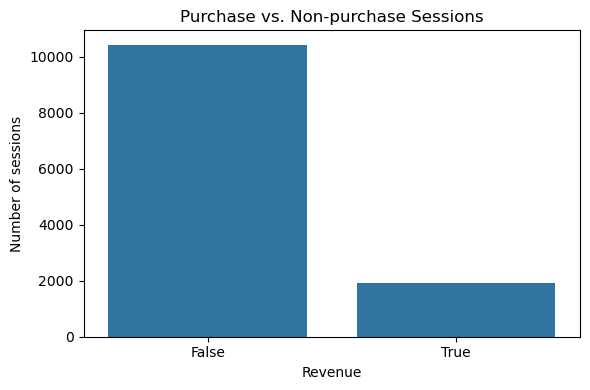

In [17]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Revenue")
plt.title("Purchase vs. Non-purchase Sessions")
plt.xlabel("Revenue")
plt.ylabel("Number of sessions")
plt.tight_layout()
plt.show()

**Insight:**

The dataset is imbalanced, as non-purchasing sessions represent approximately 84.53% of the data, while purchasing sessions account for only 15.47%. This indicates that most website visitors do not complete a purchase. Therefore, accuracy alone is not a reliable evaluation metric, and additional metrics such as Precision, Recall, F1-score, and ROC-AUC are necessary.

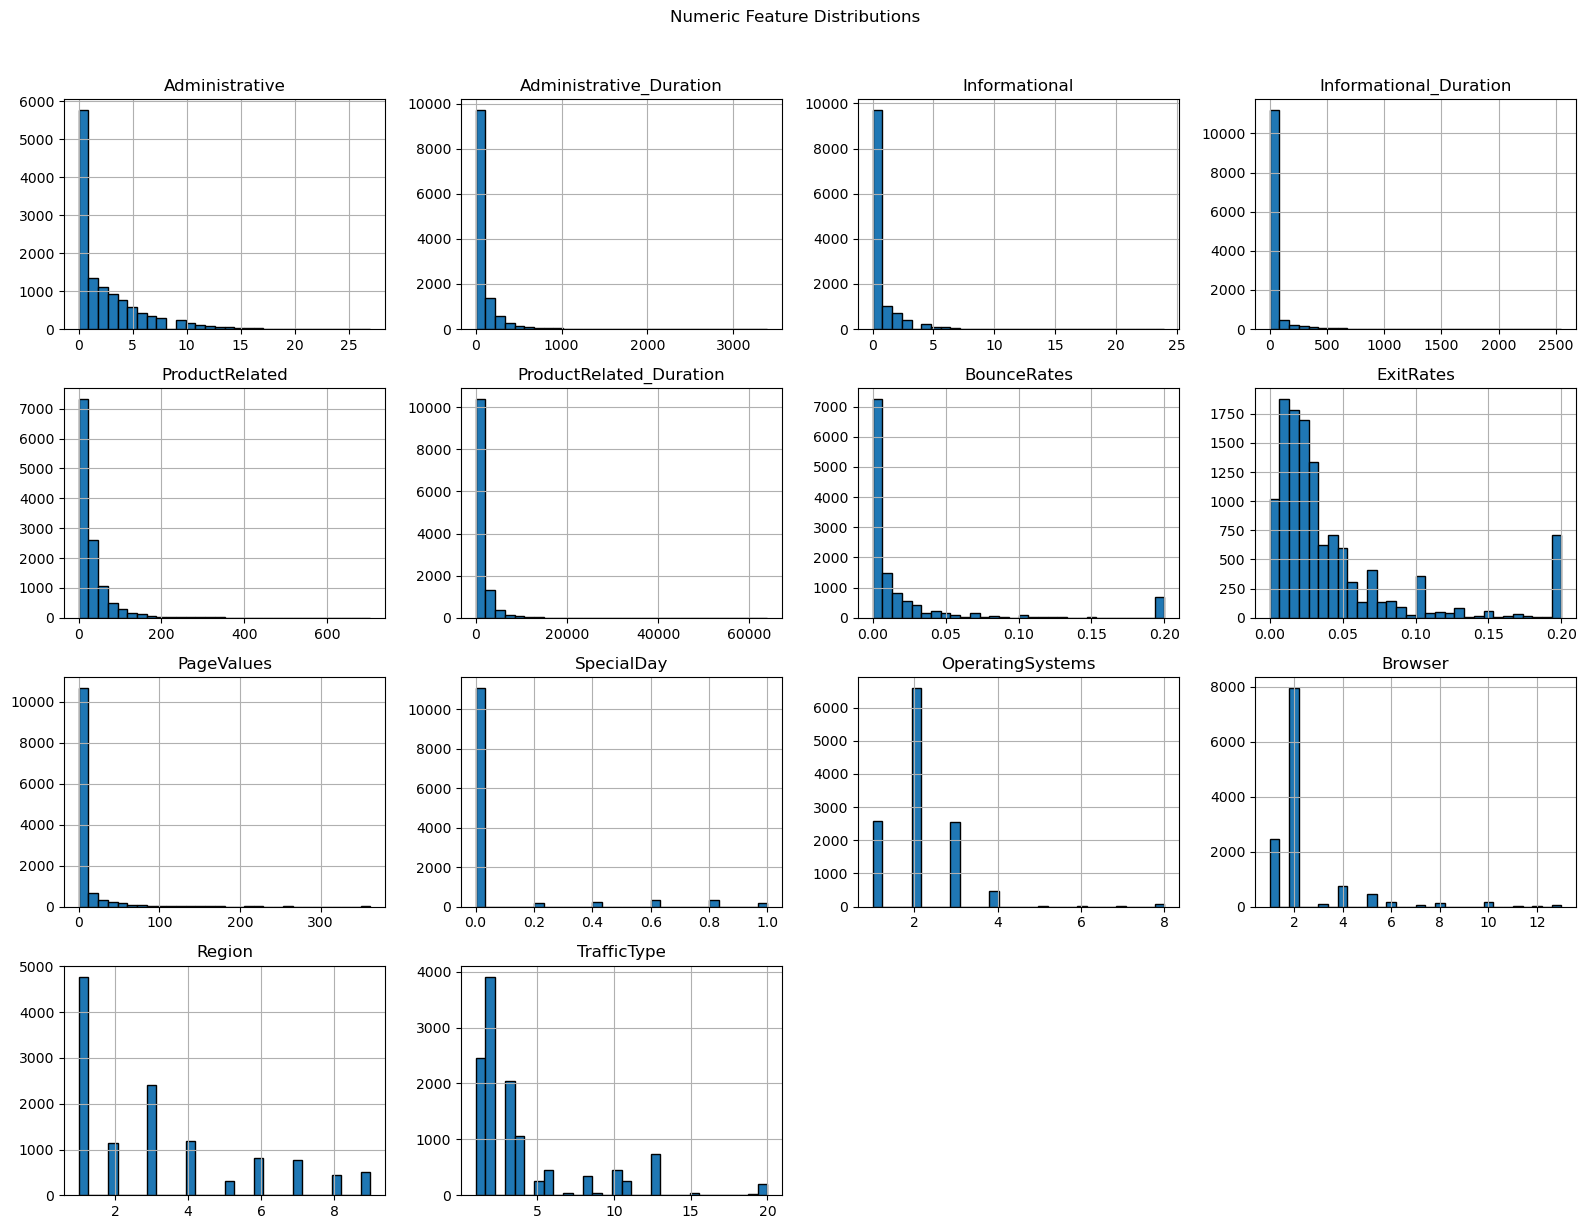

In [18]:
numeric_for_eda = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_for_eda].hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

**Insight:**

Most numerical features exhibit positively skewed distributions, with a large concentration of observations near zero and a smaller number of observations with high values. This is particularly noticeable in page duration, product-related activity, and PageValues. These distributions indicate the presence of extreme values and suggest that customer browsing behavior varies significantly across sessions.

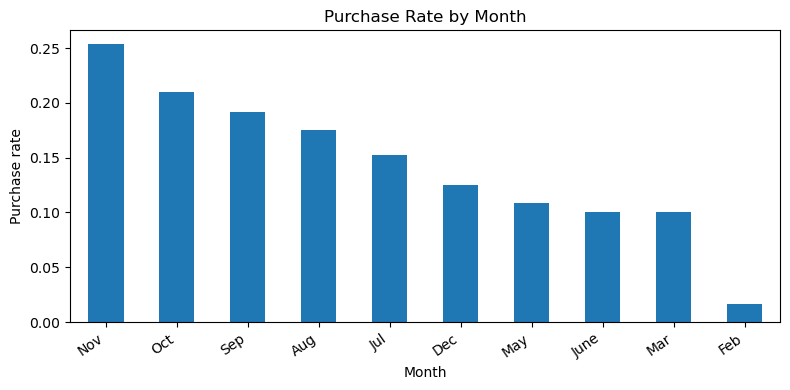

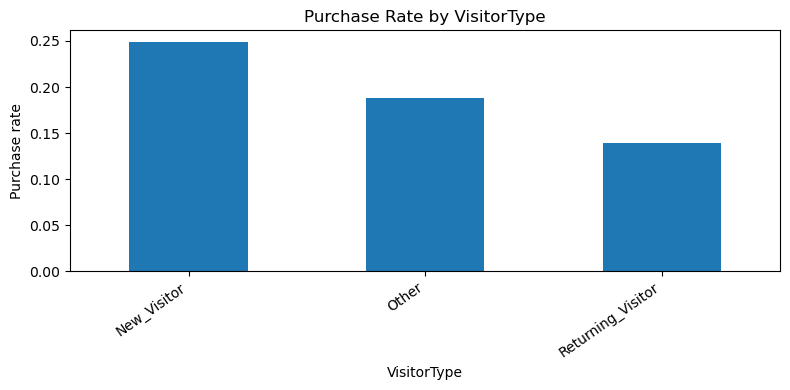

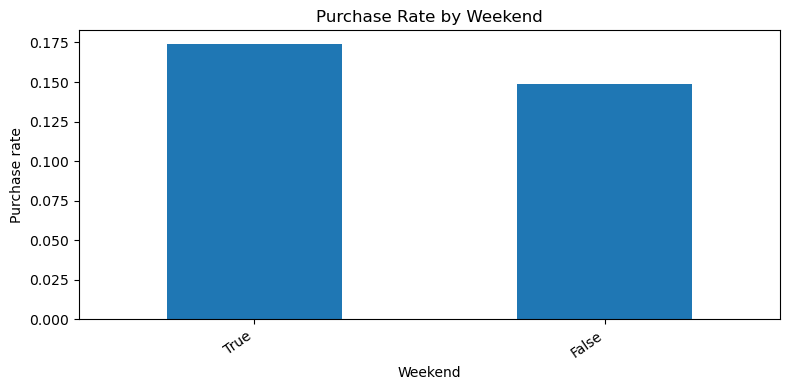

In [19]:
# Purchase rate by selected categorical variables
for col in ["Month", "VisitorType", "Weekend"]:
    if col in df.columns:
        rates = df.groupby(col, dropna=False)["Revenue"].mean().sort_values(ascending=False)
        plt.figure(figsize=(8, 4))
        rates.plot(kind="bar")
        plt.title(f"Purchase Rate by {col}")
        plt.ylabel("Purchase rate")
        plt.xlabel(col)
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()

##### 1-Purchase Rate by Month

**Insight:**

Purchase rates vary noticeably across months. November has the highest purchase rate (approximately 25%), followed by October and September. February has the lowest purchase rate. This suggests that purchasing behavior may be influenced by seasonal factors and monthly shopping trends.

##### 2-Purchase Rate by Visitor Type

**Insight:**

New visitors have the highest purchase rate (approximately 25%), followed by visitors classified as "Other" (approximately 19%). Returning visitors have a lower purchase rate of approximately 14%. This indicates that visitor type may provide useful information for understanding purchasing behavior and predicting purchase intent.


##### 3-Purchase Rate by Weekend

**Insight:**

The purchase rate is slightly higher during weekends (approximately 17.4%) compared to weekdays (approximately 14.9%). This suggests that visitors may be somewhat more likely to complete purchases during weekends, although the difference is relatively small.

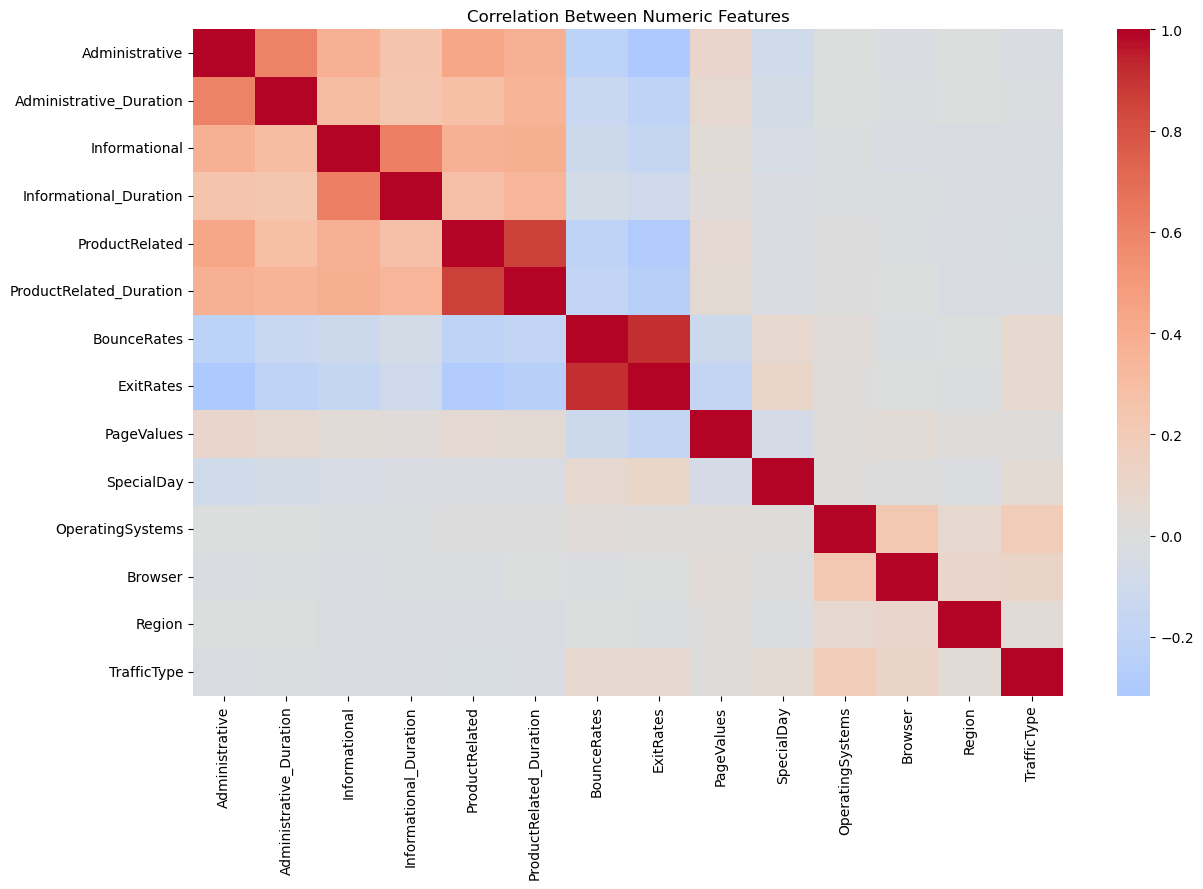

In [20]:
# Correlation heatmap for numeric features
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(13, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

**Insight:**

The correlation heatmap reveals several relationships between numerical features. ProductRelated and ProductRelated_Duration show a strong positive correlation, indicating that sessions involving more product-related pages generally have longer browsing durations. Similarly, BounceRates and ExitRates exhibit a strong positive correlation. These relationships may indicate overlapping information between some features, which should be considered during feature analysis.

In [21]:
# Compare numeric feature medians for purchasing vs non-purchasing sessions
numeric_cols_eda = df.select_dtypes(include=np.number).columns.tolist()
display(df.groupby("Revenue")[numeric_cols_eda].median().T)

Revenue,False,True
Administrative,0.000000,2.000000
Administrative_Duration,0.000000,52.366667
Informational,0.000000,0.000000
Informational_Duration,0.000000,0.000000
ProductRelated,16.000000,29.000000
ProductRelated_Duration,510.190000,1109.906250
BounceRates,0.004255,0.000000
ExitRates,0.028571,0.016000
PageValues,0.000000,16.758134
SpecialDay,0.000000,0.000000


**Insight:**

Purchasing sessions generally show higher engagement with product-related pages. The median number of ProductRelated pages is 29 for purchasing sessions compared to 16 for non-purchasing sessions. Similarly, the median ProductRelated_Duration is approximately 1109.91 seconds for purchasing sessions versus 510.19 seconds for non-purchasing sessions.

Additionally, purchasing sessions have a higher median PageValues (16.76 compared to 0) and lower median BounceRates and ExitRates. These observations suggest that deeper product exploration, higher page values, and lower exit behavior are associated with purchasing activity.

## 4. Preprocessing and leakage-safe split

We remove exact duplicate rows, separate `Revenue` from the predictors, and split the data **before fitting imputers, scalers, encoders, or models**. All learned preprocessing lives inside a scikit-learn Pipeline, so cross-validation fits it only on each training fold.

`Revenue` is never used as an input feature. It is the label used during training and optional evaluation only.

In [22]:
# Normalize target to 0/1 and remove exact duplicate rows
data = df.copy().drop_duplicates()
data["Revenue"] = data["Revenue"].map(
    lambda x: 1 if str(x).strip().lower() in {"true", "1", "yes"} else
              0 if str(x).strip().lower() in {"false", "0", "no"} else np.nan
)
data = data.dropna(subset=["Revenue"])
data["Revenue"] = data["Revenue"].astype(int)

X = data.drop(columns=["Revenue"])
y = data["Revenue"]

# Dataset-specific categorical fields: integer codes here represent categories, not quantities.
categorical_features = [
    c for c in [
        "Month", "OperatingSystems", "Browser", "Region",
        "TrafficType", "VisitorType", "Weekend"
    ] if c in X.columns
]
numeric_features = [c for c in X.columns if c not in categorical_features]

# Convert categorical columns to object dtype
X[categorical_features] = X[categorical_features].astype(object)

print("Rows after duplicate/target cleaning:", len(data))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train purchase rate:", round(y_train.mean(), 4))
print("Test purchase rate:", round(y_test.mean(), 4))

Rows after duplicate/target cleaning: 12205
Numeric features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical features: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Train shape: (9764, 17) Test shape: (2441, 17)
Train purchase rate: 0.1563
Test purchase rate: 0.1565


In [23]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [24]:
test_preprocessor = preprocessor.fit_transform(X_train)

print("Success!")
print("Shape:", test_preprocessor.shape)

Success!
Shape: (9764, 74)


## 5. Baseline and model training

We compare a majority-class baseline with three classification algorithms from the course:
1. Logistic Regression
2. Random Forest
3. Gradient Boosting

Each algorithm is placed after the preprocessing stage in a single Pipeline.

In [25]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_metrics = {
    "Model": "Majority-class baseline",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1": f1_score(y_test, baseline_pred, zero_division=0),
    "ROC-AUC": np.nan  # no meaningful probability ranking from this baseline
}
baseline_metrics

{'Model': 'Majority-class baseline',
 'Accuracy': 0.8435067595247849,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1': 0.0,
 'ROC-AUC': nan}

In [26]:
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
        {"model__C": [0.1, 1.0, 10.0]}
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {
            "model__n_estimators": [200, 400],
            "model__max_depth": [None, 15],
            "model__min_samples_leaf": [1, 2]
        }
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.05, 0.1],
            "model__max_depth": [2, 3]
        }
    )
}

## 6. Cross-validation and hyperparameter tuning

Grid search uses **training data only**, with stratified 5-fold cross-validation and ROC-AUC as the selection metric. The test set remains untouched until final evaluation.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
searches = {}
cv_rows = []

for name, (estimator, param_grid) in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )
    search.fit(X_train, y_train)
    searches[name] = search
    cv_rows.append({
        "Model": name,
        "Best CV ROC-AUC": search.best_score_,
        "Best Parameters": search.best_params_
    })

cv_results = pd.DataFrame(cv_rows).sort_values("Best CV ROC-AUC", ascending=False)
display(cv_results)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,Model,Best CV ROC-AUC,Best Parameters
2,Gradient Boosting,0.929496,"{'model__learning_rate': 0.05, 'model__max_dep..."
1,Random Forest,0.928739,"{'model__max_depth': None, 'model__min_samples..."
0,Logistic Regression,0.900535,{'model__C': 0.1}


## 7. Final evaluation on the untouched Test Set

Choose the best model by its cross-validation ROC-AUC, then evaluate it once on the held-out test set. All reported test metrics below are computed by this notebook, not estimated in advance.

In [28]:
best_name = max(searches, key=lambda name: searches[name].best_score_)
best_pipeline = searches[best_name].best_estimator_
print("Selected model:", best_name)

test_pred = best_pipeline.predict(X_test)
test_prob = best_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "Model": best_name,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob)
}
display(pd.DataFrame([baseline_metrics, test_metrics]))
print(classification_report(y_test, test_pred, target_names=["No purchase", "Purchase"]))

Selected model: Gradient Boosting


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority-class baseline,0.843507,0.000000,0.000000,0.000,NaN
1,Gradient Boosting,0.904138,0.718935,0.636126,0.675,0.936287


              precision    recall  f1-score   support

 No purchase       0.93      0.95      0.94      2059
    Purchase       0.72      0.64      0.68       382

    accuracy                           0.90      2441
   macro avg       0.83      0.79      0.81      2441
weighted avg       0.90      0.90      0.90      2441



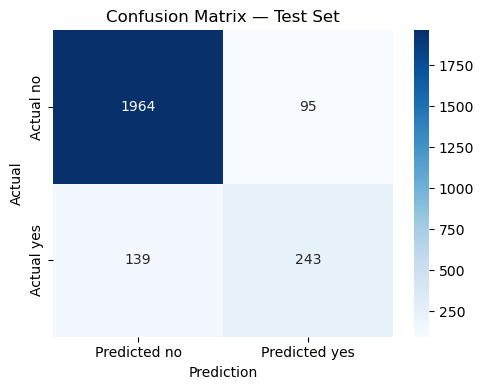

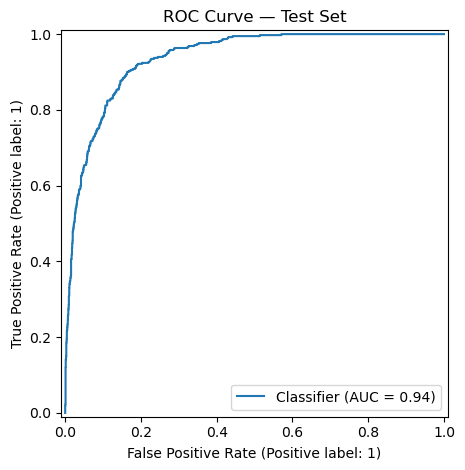

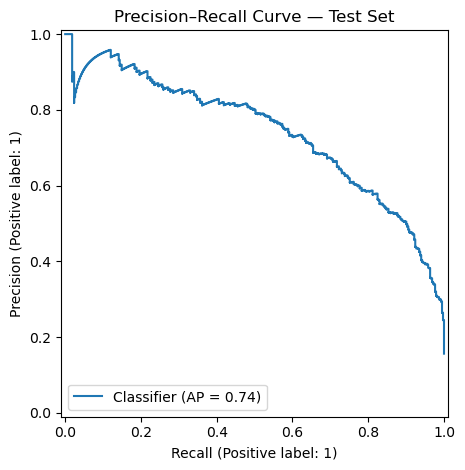

In [29]:
cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted no", "Predicted yes"],
            yticklabels=["Actual no", "Actual yes"])
plt.title("Confusion Matrix — Test Set")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title("ROC Curve — Test Set")
plt.tight_layout()
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, test_prob)
plt.title("Precision–Recall Curve — Test Set")
plt.tight_layout()
plt.show()

### Error analysis

Inspect false positives (predicted purchase, actual no purchase) and false negatives (predicted no purchase, actual purchase). Use the following cell to compare their feature values. These examples are from the held-out test set.

In [30]:
error_analysis = X_test.copy()
error_analysis["actual_Revenue"] = y_test.values
error_analysis["predicted_Revenue"] = test_pred
error_analysis["purchase_probability"] = test_prob
error_analysis["error_type"] = np.select(
    [
        (error_analysis["actual_Revenue"] == 0) & (error_analysis["predicted_Revenue"] == 1),
        (error_analysis["actual_Revenue"] == 1) & (error_analysis["predicted_Revenue"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)
display(error_analysis[error_analysis["error_type"] != "Correct"].head(20))
display(error_analysis.groupby("error_type").size().to_frame("count"))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,actual_Revenue,predicted_Revenue,purchase_probability,error_type
9976,11,250.250000,0,0.000000,169,8276.292565,0.002406,0.016052,8.174729,0.0,...,4,1,1,8,Returning_Visitor,True,0,1,0.813513,False Positive
9248,4,196.500000,3,72.500000,245,7569.248612,0.007646,0.016468,4.770910,0.0,...,3,2,1,13,Returning_Visitor,True,0,1,0.586097,False Positive
7857,10,471.060000,0,0.000000,171,5830.910000,0.001099,0.005495,0.000000,0.0,...,2,10,4,2,Returning_Visitor,False,1,0,0.047771,False Negative
4902,4,133.583333,2,64.000000,67,1222.470924,0.014414,0.025811,6.094324,0.0,...,3,2,2,4,Returning_Visitor,False,1,0,0.223789,False Negative
1415,0,0.000000,0,0.000000,10,130.166667,0.055556,0.083333,26.661333,0.0,...,3,2,1,8,Returning_Visitor,False,0,1,0.732579,False Positive
10122,3,68.285714,0,0.000000,26,741.055556,0.014286,0.039707,13.246672,0.0,...,3,2,4,10,Returning_Visitor,False,1,0,0.446103,False Negative
11542,10,302.083333,0,0.000000,81,1778.663263,0.000000,0.002857,16.437847,0.0,...,1,1,1,8,New_Visitor,True,0,1,0.738407,False Positive
9604,0,0.000000,2,485.833333,89,3747.814286,0.013636,0.030211,0.000000,0.0,...,1,1,1,2,Returning_Visitor,True,1,0,0.166108,False Negative
3967,4,120.000000,4,64.000000,52,1859.083333,0.010345,0.018391,17.248701,0.0,...,2,2,2,13,Returning_Visitor,False,1,0,0.371382,False Negative
5829,11,196.150000,0,0.000000,141,2623.580864,0.000000,0.004244,12.507865,0.0,...,2,2,6,2,Returning_Visitor,False,0,1,0.591722,False Positive


,count
error_type,
Correct,2207
False Negative,139
False Positive,95


## 8. Business insight and limitations

After running the notebook, complete this section with your measured results:
- State the best model and its test ROC-AUC, precision, recall, and F1.
- Explain what false positives and false negatives mean for the store.
- Recommend a conservative action policy and explain that action thresholds are business rules, not extra model training.
- Mention limitations: the dataset is historical and public; its patterns may not match a particular store, and a prediction is not a guarantee of purchase. The CSV uploaded to the app must use the same feature definitions and units as the training dataset.

## 9. Save the final pipeline for the application

The application loads this saved artifact. **It does not call `fit()` or retrain the model.** The feature list is saved so the app can validate incoming CSV files.

In [31]:
artifact = {
    "pipeline": best_pipeline,
    "feature_columns": X.columns.tolist(),
    "model_name": best_name,
    "threshold_note": "Business action thresholds are illustrative and can be adjusted by the store."
}
joblib.dump(artifact, OUTPUT_DIR / "purchase_intent_pipeline.joblib")
print("Saved:", OUTPUT_DIR / "purchase_intent_pipeline.joblib")

Saved: artifacts\purchase_intent_pipeline.joblib


## 10. Export an example CSV for testing the app

This file contains held-out test rows without the target column. It is a demo input file for the app, not new training data.

In [32]:
demo_csv = X_test.head(100).copy()
demo_csv.to_csv(OUTPUT_DIR / "sample_sessions_for_app.csv", index=False)
print("Saved:", OUTPUT_DIR / "sample_sessions_for_app.csv")

Saved: artifacts\sample_sessions_for_app.csv


In [33]:
import sys
import sklearn
import joblib
import numpy
import scipy

print("Python:", sys.executable)
print("sklearn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("numpy:", numpy.__version__)
print("scipy:", scipy.__version__)

Python: c:\Users\DELL\anaconda3\python.exe
sklearn: 1.7.2
joblib: 1.5.2
numpy: 2.3.5
scipy: 1.16.3
